<a href="https://colab.research.google.com/github/gayatri479/CSA4705-Deep-learning-B-SLOT/blob/main/CO-5-LAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 65 – Sequence-to-sequence LSTM encoder–decoder translation

In [2]:
pairs=[("hello","bonjour"),("good morning","bonjour"),("good night","bonne nuit"),("thank you","merci"),("how are you","comment allez vous"),("i am fine","je vais bien"),("goodbye","au revoir"),("welcome","bienvenue"),("yes","oui"),("no","non"),("please","sil vous plait"),("i love you","je taime"),("see you","a bientot"),("good evening","bonsoir"),("have a nice day","bonne journee")]
src=[a for a,b in pairs]
tgt=["<start> "+b+" <end>" for a,b in pairs]
sv=layers.TextVectorization(output_mode="int",output_sequence_length=8)
tv=layers.TextVectorization(output_mode="int",output_sequence_length=10)
sv.adapt(src)
tv.adapt(tgt)
X=sv(np.array(src))
Y=tv(np.array(tgt))
enc=layers.Input((8,))
e=layers.Embedding(len(sv.get_vocabulary()),48,mask_zero=True)(enc)
_,h,c=layers.LSTM(64,return_state=True)(e)
dec=layers.Input((9,))
de=layers.Embedding(len(tv.get_vocabulary()),48,mask_zero=True)(dec)
dl=layers.LSTM(64,return_sequences=True)
out=layers.Dense(len(tv.get_vocabulary()),activation="softmax")(dl(de,initial_state=[h,c]))
net=models.Model([enc,dec],out)
net.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
net.fit([X,Y[:,:-1]],Y[:,1:],epochs=100,batch_size=4,verbose=0)
print("Training accuracy:",net.evaluate([X,Y[:,:-1]],Y[:,1:],verbose=0)[1])
vocab=tv.get_vocabulary()
def translate(sentence):
    source=sv(np.array([sentence]))
    target=np.zeros((1,9),dtype="int32")
    target[0,0]=vocab.index("start")
    result=[]
    for i in range(8):
        probs=net.predict([source,target],verbose=0)[0,i]
        idx=int(np.argmax(probs))
        word=vocab[idx]
        if word in ["end",""]:
            break
        result.append(word)
        if i<8:
            target[0,i+1]=idx
    return " ".join(result)
for s in ["hello","thank you","good night","goodbye"]:
    print(s,"->",translate(s))

Training accuracy: 1.0
hello -> bonjour
thank you -> merci
good night -> bonne nuit
goodbye -> au revoir


## 66 – Compare RNN and LSTM for long-term dependencies

In [3]:
rng=np.random.default_rng(42)
X=rng.integers(0,2,(4000,40,1)).astype("float32")
y=X[:,0,0]
A,B,c,d=train_test_split(X,y,test_size=.2,random_state=42)
scores={}
for name,unit in [("RNN",layers.SimpleRNN(32)),("LSTM",layers.LSTM(32))]:
    m=models.Sequential([layers.Input((40,1)),unit,layers.Dense(1,activation="sigmoid")])
    m.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])
    m.fit(A,c,epochs=10,batch_size=64,verbose=0)
    scores[name]=m.evaluate(B,d,verbose=0)[1]
print(pd.Series(scores,name="Test accuracy"))

RNN     1.0000
LSTM    0.9725
Name: Test accuracy, dtype: float64


## 67 – PCA for medical data dimensionality reduction

Original shape: (600, 12)
Reduced shape: (600, 2)
Explained variance: [0.22006823 0.17283712]


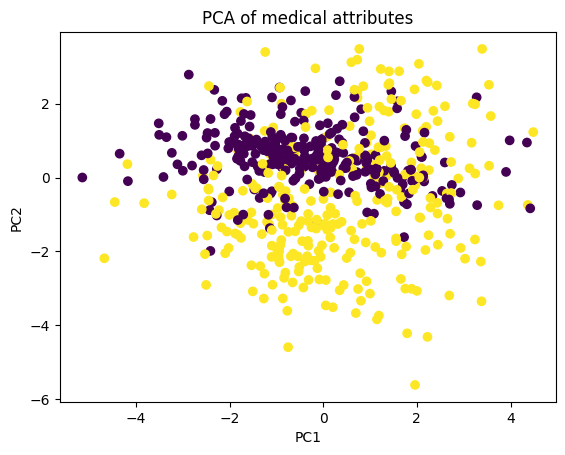

In [4]:
X,y=make_classification(n_samples=600,n_features=12,n_informative=7,n_redundant=2,random_state=42)
Z=StandardScaler().fit_transform(X)
p=PCA(n_components=2)
R=p.fit_transform(Z)
print("Original shape:",X.shape)
print("Reduced shape:",R.shape)
print("Explained variance:",p.explained_variance_ratio_)
plt.scatter(R[:,0],R[:,1],c=y)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of medical attributes")
plt.show()

## 68 – PCA on Iris dataset for classification

In [5]:
iris=load_iris()
A,B,c,d=train_test_split(iris.data,iris.target,test_size=.25,random_state=42,stratify=iris.target)
sc=StandardScaler()
A=sc.fit_transform(A)
B=sc.transform(B)
p=PCA(n_components=2)
A=p.fit_transform(A)
B=p.transform(B)
m=LogisticRegression(max_iter=1000).fit(A,c)
pred=m.predict(B)
print("Variance retained:",p.explained_variance_ratio_.sum())
print("Accuracy:",accuracy_score(d,pred))
print(classification_report(d,pred,target_names=iris.target_names))

Variance retained: 0.9603695045916796
Accuracy: 0.8947368421052632
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.80      0.92      0.86        13
   virginica       0.91      0.77      0.83        13

    accuracy                           0.89        38
   macro avg       0.90      0.90      0.90        38
weighted avg       0.90      0.89      0.89        38



## 69 – Visualize high-dimensional data using first two principal components

Original dimensions: 8
Reduced dimensions: 2
Variance retained: 0.787967914883914


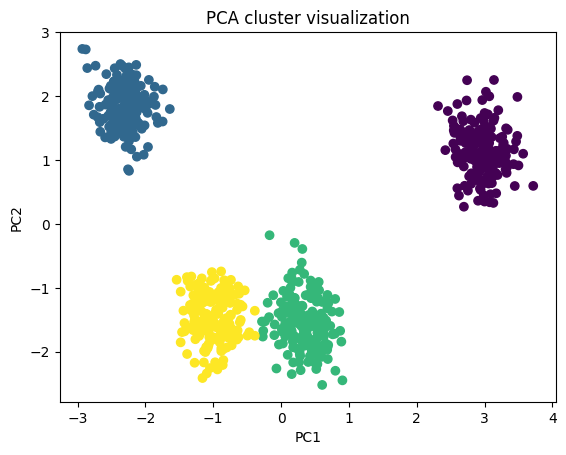

In [6]:
X,y=make_blobs(n_samples=700,n_features=8,centers=4,random_state=42)
Z=StandardScaler().fit_transform(X)
p=PCA(n_components=2)
R=p.fit_transform(Z)
print("Original dimensions:",X.shape[1])
print("Reduced dimensions:",R.shape[1])
print("Variance retained:",p.explained_variance_ratio_.sum())
plt.scatter(R[:,0],R[:,1],c=y,cmap="viridis")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA cluster visualization")
plt.show()

## 70 – Classification before and after PCA

In [7]:
X,y=make_classification(n_samples=1200,n_features=20,n_informative=8,n_redundant=6,random_state=42)
A,B,c,d=train_test_split(X,y,test_size=.25,random_state=42,stratify=y)
sc=StandardScaler()
A=sc.fit_transform(A)
B=sc.transform(B)
from sklearn.ensemble import RandomForestClassifier
m1=RandomForestClassifier(n_estimators=120,random_state=42).fit(A,c)
p1=m1.predict(B)
pca=PCA(n_components=8)
A2=pca.fit_transform(A)
B2=pca.transform(B)
m2=RandomForestClassifier(n_estimators=120,random_state=42).fit(A2,c)
p2=m2.predict(B2)
print("Accuracy before PCA:",accuracy_score(d,p1))
print("Accuracy after PCA:",accuracy_score(d,p2))
print("Variance retained:",pca.explained_variance_ratio_.sum())

Accuracy before PCA: 0.8866666666666667
Accuracy after PCA: 0.82
Variance retained: 0.7663028924473417


## 71 – Number of principal components for 95% variance

Explained variance: [2.31048246e-01 1.20264159e-01 8.39560885e-02 6.80417122e-02
 6.20645812e-02 5.32884525e-02 4.47496379e-02 4.20680965e-02
 4.03771775e-02 3.93408556e-02 3.89896992e-02 3.73026015e-02
 3.57653383e-02 3.39183510e-02 2.89008523e-02 2.49561726e-02
 1.49679783e-02 3.65875200e-17 2.46632377e-17 2.00658267e-17
 1.56221637e-17 2.57265223e-18 0.00000000e+00 0.00000000e+00
 0.00000000e+00]
Cumulative variance: [0.23104825 0.3513124  0.43526849 0.50331021 0.56537479 0.61866324
 0.66341288 0.70548097 0.74585815 0.78519901 0.82418871 0.86149131
 0.89725665 0.931175   0.96007585 0.98503202 1.         1.
 1.         1.         1.         1.         1.         1.
 1.        ]
Components for 95%: 15
Variance retained: 0.9600758491423755


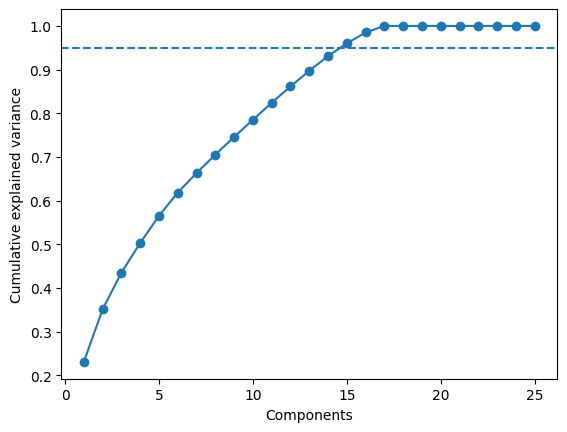

In [8]:
X,y=make_classification(n_samples=800,n_features=25,n_informative=10,n_redundant=8,random_state=42)
Z=StandardScaler().fit_transform(X)
p=PCA().fit(Z)
cum=np.cumsum(p.explained_variance_ratio_)
n=np.argmax(cum>=.95)+1
print("Explained variance:",p.explained_variance_ratio_)
print("Cumulative variance:",cum)
print("Components for 95%:",n)
print("Variance retained:",cum[n-1])
plt.plot(range(1,len(cum)+1),cum,marker="o")
plt.axhline(.95,linestyle="--")
plt.xlabel("Components")
plt.ylabel("Cumulative explained variance")
plt.show()

## 72 – ICA for mixed sound-source separation

Mixed shape: (8000, 3)
Separated shape: (8000, 3)


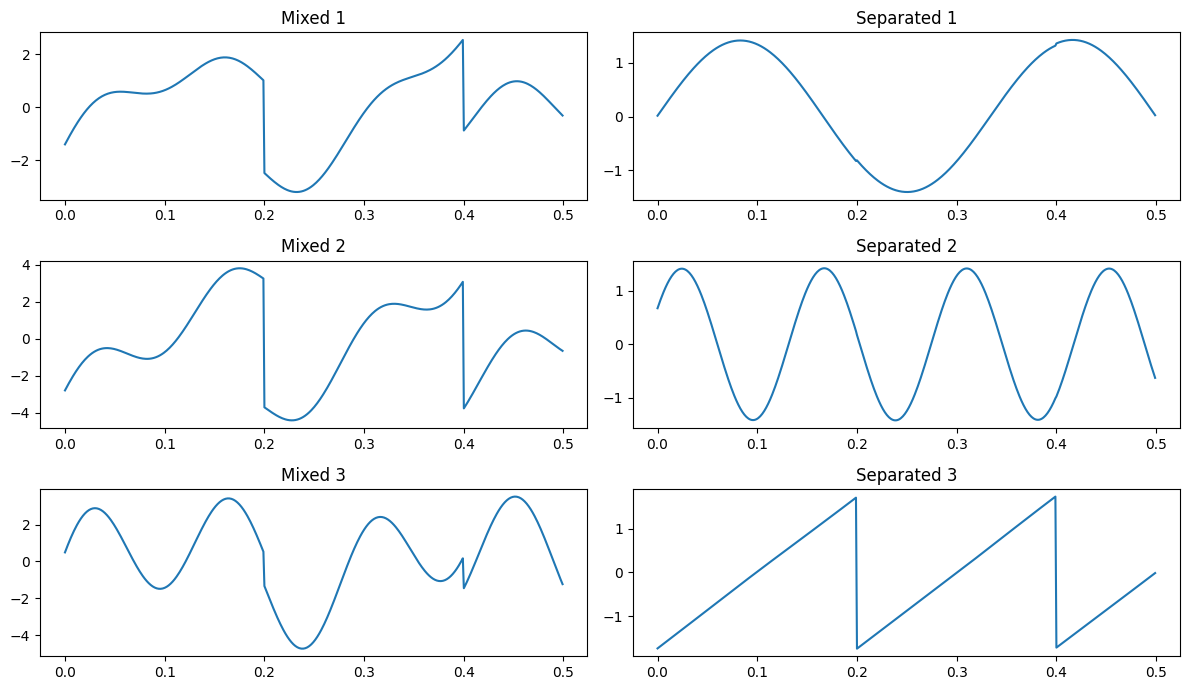

In [9]:
from scipy import signal
t=np.linspace(0,8,8000)
S=np.c_[np.sin(2*np.pi*3*t),signal.sawtooth(2*np.pi*5*t),np.sin(2*np.pi*7*t+.5)]
S=StandardScaler().fit_transform(S)
M=np.array([[1,1,.5],[.5,2,1],[1,.5,2]])
mixed=S@M.T
ica=FastICA(n_components=3,random_state=42,max_iter=2000)
separated=ica.fit_transform(mixed)
print("Mixed shape:",mixed.shape)
print("Separated shape:",separated.shape)
fig,ax=plt.subplots(3,2,figsize=(12,7))
for i in range(3):
    ax[i,0].plot(t[:500],mixed[:500,i])
    ax[i,0].set_title("Mixed "+str(i+1))
    ax[i,1].plot(t[:500],separated[:500,i])
    ax[i,1].set_title("Separated "+str(i+1))
plt.tight_layout()
plt.show()

## 73 – ICA blind source separation for two voice-like signals

Component 1 best absolute correlation: 0.9999999933571586
Component 2 best absolute correlation: 0.9999999344651599


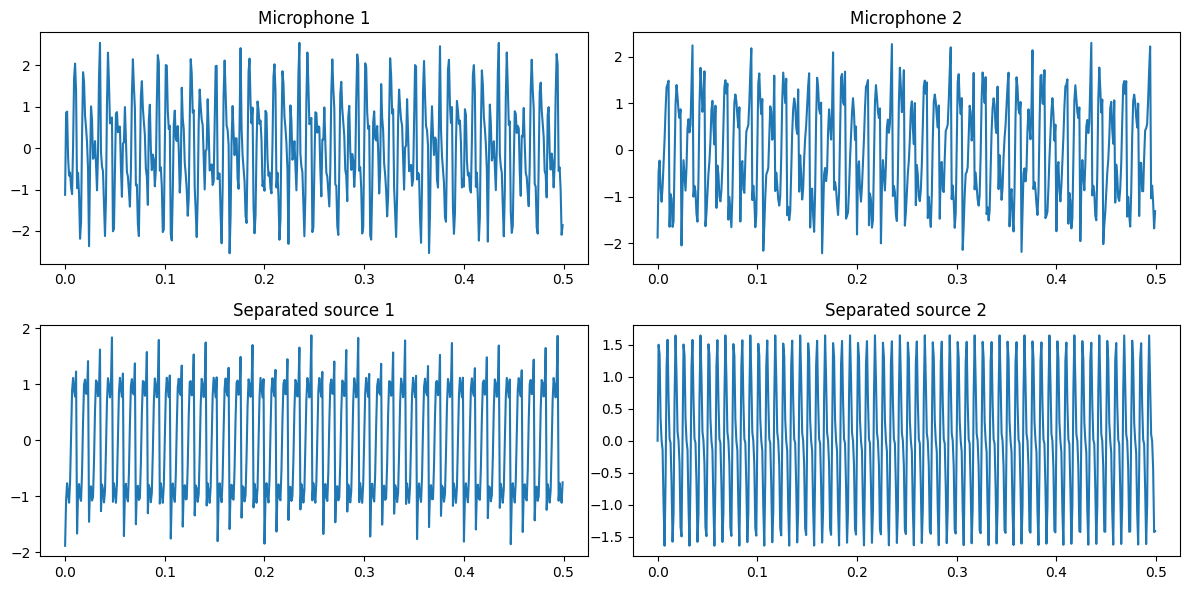

In [10]:
from scipy import signal
t=np.linspace(0,5,5000)
S=np.c_[np.sin(2*np.pi*120*t)+.5*np.sin(2*np.pi*240*t),signal.sawtooth(2*np.pi*85*t)+.3*np.sin(2*np.pi*170*t)]
S=StandardScaler().fit_transform(S)
M=np.array([[1,.6],[.4,1]])
mixed=S@M.T
ica=FastICA(n_components=2,random_state=42,max_iter=2000)
R=ica.fit_transform(mixed)
for i in range(2):
    print("Component",i+1,"best absolute correlation:",max(abs(np.corrcoef(S[:,j],R[:,i])[0,1]) for j in range(2)))
fig,ax=plt.subplots(2,2,figsize=(12,6))
ax[0,0].plot(t[:500],mixed[:500,0]); ax[0,0].set_title("Microphone 1")
ax[0,1].plot(t[:500],mixed[:500,1]); ax[0,1].set_title("Microphone 2")
ax[1,0].plot(t[:500],R[:500,0]); ax[1,0].set_title("Separated source 1")
ax[1,1].plot(t[:500],R[:500,1]); ax[1,1].set_title("Separated source 2")
plt.tight_layout()
plt.show()

## 74 – Compare PCA and ICA for feature extraction

In [11]:
from scipy import signal
t=np.linspace(0,8,3000)
S=np.c_[np.sin(2*t),np.sign(np.sin(3*t)),signal.sawtooth(5*t)]
S+=.05*np.random.normal(size=S.shape)
M=np.array([[1,1,.5],[.5,2,1],[1,.5,2]])
Z=StandardScaler().fit_transform(S@M.T)
p=PCA(n_components=3).fit_transform(Z)
i=FastICA(n_components=3,random_state=42,max_iter=2000).fit_transform(Z)
print("PCA component variances:",np.var(p,axis=0))
print("ICA component variances:",np.var(i,axis=0))
print("PCA component correlations:")
print(np.round(np.corrcoef(p.T),3))
print("ICA component correlations:")
print(np.round(np.corrcoef(i.T),3))

PCA component variances: [2.52302547 0.40916608 0.06780846]
ICA component variances: [1. 1. 1.]
PCA component correlations:
[[ 1.  0. -0.]
 [ 0.  1. -0.]
 [-0. -0.  1.]]
ICA component correlations:
[[ 1. -0.  0.]
 [-0.  1. -0.]
 [ 0. -0.  1.]]


## 75 – Factor analysis of student academic performance

               Factor 1  Factor 2
Marks             0.948     0.081
Attendance        0.253    -0.724
Assignments       0.904    -0.093
Participation     0.311    -0.838
Quiz              0.848     0.309


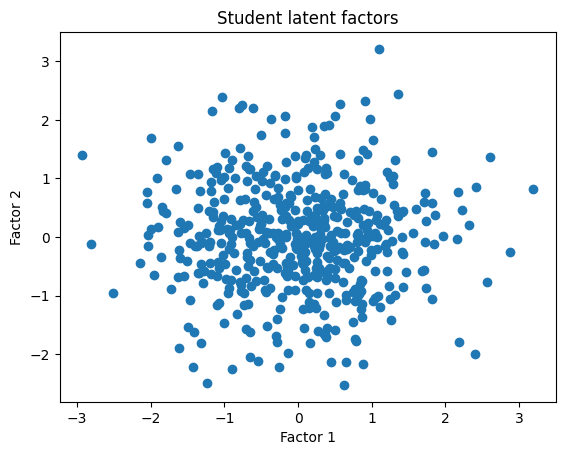

In [12]:
rng=np.random.default_rng(42)
n=500
study=rng.normal(size=n)
engage=rng.normal(size=n)
df=pd.DataFrame({"Marks":70+10*study+3*engage+rng.normal(0,3,n),"Attendance":75+5*engage+rng.normal(0,4,n),"Assignments":70+8*study+4*engage+rng.normal(0,4,n),"Participation":60+10*engage+rng.normal(0,5,n),"Quiz":68+9*study+rng.normal(0,4,n)})
Z=StandardScaler().fit_transform(df)
fa=FactorAnalysis(n_components=2,random_state=42)
scores=fa.fit_transform(Z)
print(pd.DataFrame(fa.components_.T,index=df.columns,columns=["Factor 1","Factor 2"]).round(3))
plt.scatter(scores[:,0],scores[:,1])
plt.xlabel("Factor 1")
plt.ylabel("Factor 2")
plt.title("Student latent factors")
plt.show()

## 76 – Factor analysis of customer purchasing behaviour

In [13]:
rng=np.random.default_rng(7)
n=600
price=rng.normal(size=n)
loyal=rng.normal(size=n)
df=pd.DataFrame({"Discount_Purchases":50+12*price+rng.normal(0,4,n),"Coupon_Use":45+10*price+rng.normal(0,5,n),"Premium_Spending":60+12*loyal-5*price+rng.normal(0,5,n),"Repeat_Purchases":55+10*loyal+rng.normal(0,4,n),"Brand_Visits":50+8*loyal+rng.normal(0,5,n),"Monthly_Orders":30+7*loyal+4*price+rng.normal(0,4,n)})
Z=StandardScaler().fit_transform(df)
fa=FactorAnalysis(n_components=2,random_state=42)
scores=fa.fit_transform(Z)
print("Factor loadings:")
print(pd.DataFrame(fa.components_.T,index=df.columns,columns=["Factor 1","Factor 2"]).round(3))
print("Customer factor scores:")
print(pd.DataFrame(scores,columns=["Factor 1","Factor 2"]).head(10))

Factor loadings:
                    Factor 1  Factor 2
Discount_Purchases     0.130    -0.928
Coupon_Use             0.084    -0.879
Premium_Spending      -0.889     0.239
Repeat_Purchases      -0.923    -0.110
Brand_Visits          -0.854    -0.074
Monthly_Orders        -0.711    -0.528
Customer factor scores:
   Factor 1  Factor 2
0  1.739506  0.248612
1 -0.519317 -0.465072
2 -0.180897  0.339683
3 -0.229832  0.573352
4  1.419033  0.870193
5  0.395136  1.018764
6  0.928079 -0.123548
7  1.318449 -1.573237
8  1.986106  0.428224
9  0.280602  0.372358


## 77 – Compare PCA and factor analysis using reconstruction error

In [14]:
rng=np.random.default_rng(42)
latent=rng.normal(size=(700,2))
loading=rng.normal(size=(2,8))
X=latent@loading+rng.normal(0,.5,size=(700,8))
X=StandardScaler().fit_transform(X)
p=PCA(n_components=2)
ps=p.fit_transform(X)
pr=p.inverse_transform(ps)
fa=FactorAnalysis(n_components=2,random_state=42)
fs=fa.fit_transform(X)
fr=fs@fa.components_+fa.mean_
pe=mean_squared_error(X,pr)
fe=mean_squared_error(X,fr)
print("PCA reconstruction MSE:",pe)
print("Factor Analysis reconstruction MSE:",fe)
print("PCA variance retained:",p.explained_variance_ratio_.sum())
print("Lower reconstruction error:", "PCA" if pe<fe else "Factor Analysis")

PCA reconstruction MSE: 0.1620133487255791
Factor Analysis reconstruction MSE: 0.1782268004911565
PCA variance retained: 0.837986651274421
Lower reconstruction error: PCA


## 78 – Generate and analyse multivariate Gaussian data

Data shape: (2000, 3)
Original mean: [  25.   60. 1012.]
Estimated mean: [  25.09386919   59.87127404 1012.1799006 ]
Original covariance:
[[ 4.   1.2  0.5]
 [ 1.2 25.   2. ]
 [ 0.5  2.  16. ]]
Estimated covariance:
[[ 3.86416651  0.97192906  0.42263602]
 [ 0.97192906 24.61485627  1.67847831]
 [ 0.42263602  1.67847831 15.93868483]]


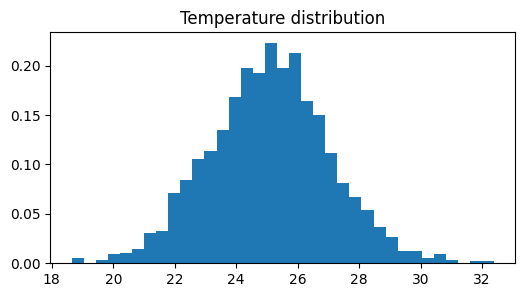

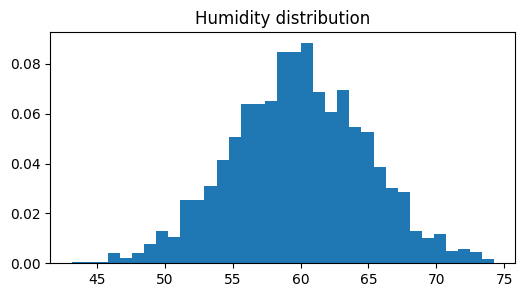

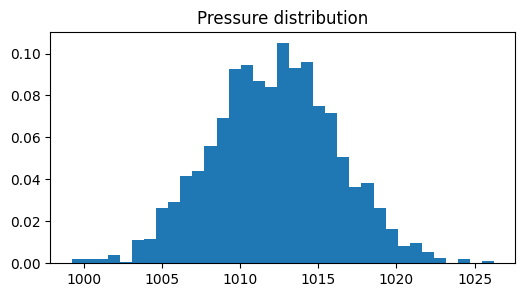

In [15]:
mean=np.array([25.,60.,1012.])
cov=np.array([[4.,1.2,.5],[1.2,25.,2.],[.5,2.,16.]])
data=np.random.multivariate_normal(mean,cov,size=2000)
print("Data shape:",data.shape)
print("Original mean:",mean)
print("Estimated mean:",data.mean(axis=0))
print("Original covariance:")
print(cov)
print("Estimated covariance:")
print(np.cov(data,rowvar=False))
for j,name in enumerate(["Temperature","Humidity","Pressure"]):
    plt.figure(figsize=(6,3))
    plt.hist(data[:,j],bins=35,density=True)
    plt.title(name+" distribution")
    plt.show()

## 79 – Gaussian Mixture Model for customer segmentation

Cluster counts:
0    175
1    173
2    175
3    177
Name: count, dtype: int64
Membership probabilities:
      Cluster_0     Cluster_1     Cluster_2     Cluster_3
0  5.438436e-24  1.864201e-08  1.000000e+00  5.476001e-18
1  1.000000e+00  3.590239e-27  5.063452e-20  4.746763e-16
2  4.047523e-30  7.738174e-09  7.841905e-30  1.000000e+00
3  1.139164e-24  7.616760e-11  2.183055e-29  1.000000e+00
4  3.881909e-35  5.885509e-16  1.000000e+00  5.274811e-30
5  6.702003e-28  9.998599e-01  2.864784e-11  1.400870e-04
6  7.583817e-27  2.446194e-13  1.000000e+00  2.870699e-24
7  6.252350e-34  1.000000e+00  7.199211e-09  1.483658e-08
8  8.170485e-38  9.999998e-01  6.101405e-13  1.721666e-07
9  4.629382e-33  1.103353e-17  1.000000e+00  4.888241e-31
Silhouette score: 0.7131237732135106


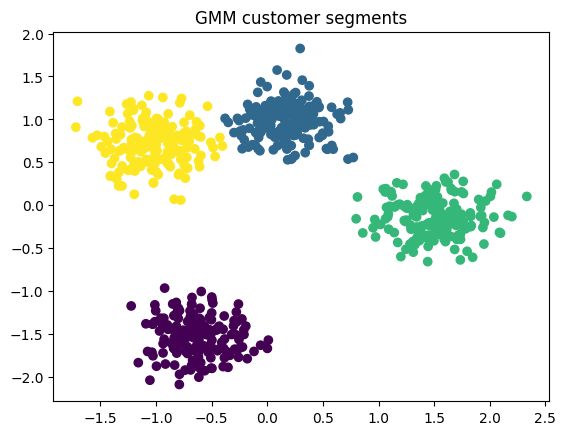

In [16]:
X,y=make_blobs(n_samples=700,centers=4,n_features=2,cluster_std=1.4,random_state=42)
Z=StandardScaler().fit_transform(X)
g=GaussianMixture(n_components=4,random_state=42).fit(Z)
cluster=g.predict(Z)
probs=g.predict_proba(Z)
print("Cluster counts:")
print(pd.Series(cluster).value_counts().sort_index())
print("Membership probabilities:")
print(pd.DataFrame(probs,columns=[f"Cluster_{i}" for i in range(4)]).head(10))
print("Silhouette score:",silhouette_score(Z,cluster))
plt.scatter(Z[:,0],Z[:,1],c=cluster,cmap="viridis")
plt.title("GMM customer segments")
plt.show()

## 80 – Deep learning healthcare prediction application

Epoch 1/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.6780 - loss: 0.6379 - precision: 0.6126 - recall: 0.4574 - val_accuracy: 0.8785 - val_loss: 0.5188 - val_precision: 0.9286 - val_recall: 0.7939
Epoch 2/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8073 - loss: 0.4899 - precision: 0.8043 - recall: 0.6637 - val_accuracy: 0.8889 - val_loss: 0.3766 - val_precision: 0.9024 - val_recall: 0.8473
Epoch 3/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8533 - loss: 0.3757 - precision: 0.8274 - recall: 0.7848 - val_accuracy: 0.8889 - val_loss: 0.2901 - val_precision: 0.8960 - val_recall: 0.8550
Epoch 4/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8811 - loss: 0.3104 - precision: 0.8488 - recall: 0.8430 - val_accuracy: 0.9097 - val_loss: 0.2506 - val_precision: 0.9008 - val_recall: 0.9008
Epoch 5/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8915 - loss: 0.2853 - precision: 0.8639 - recall: 0.8543 - val_accuracy: 0.9306 - val_loss: 0.2351 - va

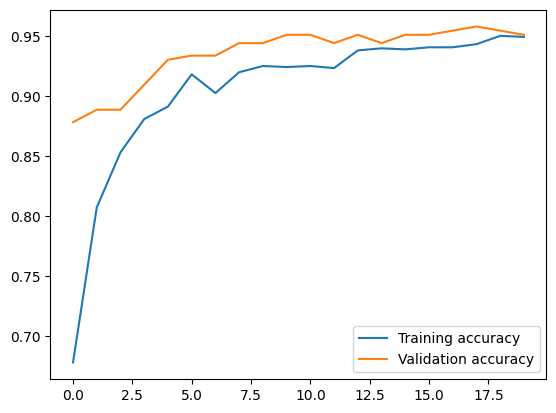

Predicted risk probability: 0.00015153588901739568
Predicted category: Lower risk


In [17]:
X,y=make_classification(n_samples=1800,n_features=14,n_informative=9,n_redundant=3,weights=[.6,.4],random_state=42)
A,B,c,d=train_test_split(X,y,test_size=.2,random_state=42,stratify=y)
sc=StandardScaler()
A=sc.fit_transform(A)
B=sc.transform(B)
health=models.Sequential([layers.Input((A.shape[1],)),layers.Dense(64,activation="relu"),layers.Dropout(.3),layers.Dense(32,activation="relu"),layers.Dropout(.2),layers.Dense(16,activation="relu"),layers.Dense(1,activation="sigmoid")])
health.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy",tf.keras.metrics.Precision(),tf.keras.metrics.Recall()])
history=health.fit(A,c,epochs=20,batch_size=32,validation_split=.2,verbose=1)
print("Test metrics:",health.evaluate(B,d,verbose=0))
pred=(health.predict(B,verbose=0).flatten()>=.5).astype(int)
print(classification_report(d,pred))
plt.plot(history.history["accuracy"],label="Training accuracy")
plt.plot(history.history["val_accuracy"],label="Validation accuracy")
plt.legend()
plt.show()
prob=float(health.predict(B[:1],verbose=0)[0,0])
print("Predicted risk probability:",prob)
print("Predicted category:","Higher risk" if prob>=.5 else "Lower risk")